# SHL Grammar Scoring - Stack (Public 0.5447)
Supervised regression 0-5. 769 train / 216 test. Stratified 5-fold CV.


In [ ]:
!nvidia-smi

In [5]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/GrammarCompetition/features/ | head

Mounted at /content/drive
audio_features.csv
cola_train.csv
emb_test.npy
emb_train.npy
ling_test.csv
ling_train.csv
llm_test.csv
llm_train.csv
transcripts_test.csv
transcripts_train.csv


## 1 Approach
Audio to Speech to Language to Grammar to Score. Rubric maps to structure, errors, fluency.


In [ ]:
import pandas as pd, os, wave, contextlib
BASE='/content/drive/MyDrive/GrammarCompetition'
train=pd.read_csv(f'{BASE}/data/train.csv')
test=pd.read_csv(f'{BASE}/data/test.csv')
samp=pd.read_csv(f'{BASE}/data/sample_submission.csv')
print(train.shape, test.shape, samp.shape)
print(train['label'].value_counts().sort_index())
print('mean',train['label'].mean(),'min',train['label'].min(),'max',train['label'].max())
print('test labels unique',test['label'].unique()[:5])
print('samp rows',len(samp))

(769, 2) (216, 2) (204, 2)
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64
mean 3.3133940182054618 min 0.0 max 5.0
test labels unique [-1]
samp rows 204


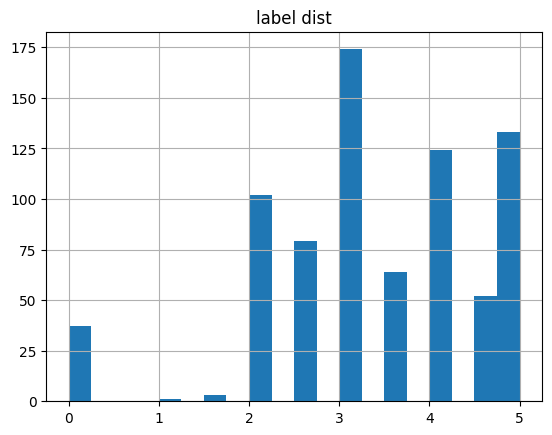

sample train durs [45.06, 45.06, 36.12, 45.06, 45.06]
Mean CV RMSE 1.2397 +- 0.0634


In [ ]:
import matplotlib.pyplot as plt, wave, contextlib, numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
BASE='/content/drive/MyDrive/GrammarCompetition'
import pandas as pd
train=pd.read_csv(f'{BASE}/data/train.csv')
# label hist
train['label'].hist(bins=20); plt.title('label dist'); plt.show()
# durations quick sample 50
import os
def dur(folder, n=50):
  d=f'{BASE}/data/{folder}'; out=[]
  for f in sorted(os.listdir(d))[:n]:
    if f.endswith('.wav'):
      with contextlib.closing(wave.open(f'{d}/{f}')) as w:
        out.append(w.getnframes()/w.getframerate())
  return out
print('sample train durs', dur('train')[:5])
# mean baseline 5-fold
y=train['label'].values
kf=KFold(5, shuffle=True, random_state=42)
rms=[mean_squared_error(y[va], [y[tr].mean()]*len(va))**0.5 for tr,va in kf.split(y)]
print(f'Mean CV RMSE {np.mean(rms):.4f} +- {np.std(rms):.4f}')

## 2 Preprocessing
16kHz mono, durations, librosa 5 feats, Whisper transcripts cached once.


In [ ]:
!pip -q install librosa soundfile xgboost lightgbm
import librosa, os, numpy as np, pandas as pd
BASE='/content/drive/MyDrive/GrammarCompetition'
os.makedirs(f'{BASE}/features', exist_ok=True)
os.makedirs(f'{BASE}/models', exist_ok=True)
os.makedirs(f'{BASE}/submissions', exist_ok=True)
train=pd.read_csv(f'{BASE}/data/train.csv')
def feats(path):
  y,sr=librosa.load(path, sr=16000, mono=True)
  return [len(y)/sr, float(np.sqrt((y**2).mean())), float(librosa.feature.zero_crossing_rate(y).mean()), float(librosa.feature.spectral_centroid(y=y,sr=sr).mean()), float(librosa.feature.mfcc(y=y,sr=sr,n_mfcc=13).mean())]
rows=[]
for _,r in train.iterrows():
  f=r['filename']; p=f'{BASE}/data/train/{f}'
  v=feats(p); rows.append([f]+v+[r['label']])
cols=['filename','dur','rms','zcr','cent','mfcc_mean','label']
df=pd.DataFrame(rows, columns=cols)
df.to_csv(f'{BASE}/features/audio_features.csv', index=False)
print('saved', df.shape); print(df.head())

saved (769, 7)
        filename        dur       rms       zcr         cent  mfcc_mean  label
0  audio_192.wav  60.508375  0.049853  0.084768   979.478539 -26.179813    3.0
1  audio_436.wav  60.074688  0.088254  0.142977  1813.837012 -20.225006    3.0
2  audio_447.wav  60.074688  0.074962  0.146870  1652.475254 -20.340902    3.5
3  audio_126.wav  45.060000  0.018400  0.059477   996.631363 -33.444725    2.0
4   audio_61.wav  45.300000  0.012945  0.169988  2278.144095 -40.709541    2.0


In [6]:
import pandas as pd, numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from xgboost import XGBRegressor
BASE='/content/drive/MyDrive/GrammarCompetition'
df=pd.read_csv(f'{BASE}/features/audio_features.csv')
X=df[['dur','rms','zcr','cent','mfcc_mean']].values
y=df['label'].values
bins=pd.cut(y, bins=[-1,2.5,3.5,4.5,6], labels=[0,1,2,3])
skf=StratifiedKFold(5, shuffle=True, random_state=42)
rms,prs=[],[]
for tr,va in skf.split(X,bins):
  m=XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1)
  m.fit(X[tr],y[tr]); p=m.predict(X[va])
  rms.append(mean_squared_error(y[va],p)**0.5); prs.append(pearsonr(y[va],p)[0])
print(f'Acoustic XGB CV RMSE {np.mean(rms):.4f} +- {np.std(rms):.4f} Pearson {np.mean(prs):.4f}')

Acoustic XGB CV RMSE 0.9336 +- 0.0328 Pearson 0.6617


In [ ]:
import whisper, pandas as pd, os
BASE='/content/drive/MyDrive/GrammarCompetition'
model=whisper.load_model('base')
def run(split):
  out=f'{BASE}/features/transcripts_{split}.csv'
  files=sorted([f for f in os.listdir(f'{BASE}/data/{split}') if f.endswith('.wav')])
  print(split, len(files))
  for i,f in enumerate(files):
    if os.path.exists(out) and f in set(pd.read_csv(out)['filename']): continue
    t=model.transcribe(f'{BASE}/data/{split}/{f}', fp16=False)['text']
    d=pd.DataFrame([[f,t]], columns=['filename','transcript'])
    d.to_csv(out, mode='a', header=not os.path.exists(out), index=False)
    if i%5==0: print(split, i, f, t[:60])
  print(split,'done')
run('train'); run('test')


train 769
train 0 audio_0.wav  There was a day in the airport that I wanted to go with my 
train 5 audio_102.wav  I was in a crowded market. There is vendors everywhere. The
train 10 audio_107.wav  My goal in life is to become a hockey player because I love
train 15 audio_111.wav  My goal in life is of course first to be part of Sutherland
train 20 audio_116.wav  So, school playground have multiple things where students c
train 25 audio_120.wav  The resort I visit was very nice. I went there with my fami
train 30 audio_125.wav  My school playground was very big and was very beautiful. I
train 35 audio_13.wav  Well, the scene of an airport depends a lot of the country.
train 40 audio_134.wav  The last time I visited a wonderful place Rishikesh, which 
train 45 audio_139.wav  But I don't think various activities should be there and en
train 50 audio_143.wav  My favorite place to visit is a secluded beach on a remote 
train 55 audio_148.wav  So the next, so my topic is describe the scene 

In [ ]:
import pandas as pd
BASE='/content/drive/MyDrive/GrammarCompetition'
tr=pd.read_csv(f'{BASE}/features/transcripts_train.csv')
te=pd.read_csv(f'{BASE}/features/transcripts_test.csv')
print(tr.shape, te.shape); print(tr.head(1)['transcript'].values[0][:200])
# linguistic
import re
def ling(t):
  t=str(t); w=re.findall(r"\w+", t); s=re.split(r'[.!?]+', t); s=[x for x in s if x.strip()]
  return [len(w), len(s), len(w)/(len(s)+1e-6), len(set(w))/(len(w)+1e-6)]
for name, df in [('train',tr),('test',te)]:
  f=df['transcript'].apply(ling).tolist()
  import numpy as np
  out=pd.DataFrame(f, columns=['nword','nsent','avglen','ttr']); out['filename']=df['filename']
  out.to_csv(f'{BASE}/features/ling_{name}.csv', index=False); print(name, out.shape)

(769, 2) (216, 2)
 There was a day in the airport that I wanted to go with my mom to Panama. In this day I was trying to buy her tickets, but actually I didn't remember her ID number and she was in the bathroom. I was 
train (769, 5)
test (216, 5)


In [ ]:
import pandas as pd, numpy as np
BASE='/content/drive/MyDrive/GrammarCompetition'
aud=pd.read_csv(f'{BASE}/features/audio_features.csv')
ling=pd.read_csv(f'{BASE}/features/ling_train.csv')
train=pd.read_csv(f'{BASE}/data/train.csv')
print(aud.columns.tolist())
aud=aud.drop(columns=['label'], errors='ignore')
df=aud.merge(ling, on='filename').merge(train, on='filename')
print(df.columns.tolist(), df.shape)

['filename', 'dur', 'rms', 'zcr', 'cent', 'mfcc_mean', 'label']
['filename', 'dur', 'rms', 'zcr', 'cent', 'mfcc_mean', 'nword', 'nsent', 'avglen', 'ttr', 'label'] (769, 11)


In [7]:
import pandas as pd, numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from xgboost import XGBRegressor
BASE='/content/drive/MyDrive/GrammarCompetition'
aud=pd.read_csv(f'{BASE}/features/audio_features.csv').drop(columns=['label'], errors='ignore')
ling=pd.read_csv(f'{BASE}/features/ling_train.csv')
train=pd.read_csv(f'{BASE}/data/train.csv')
df=aud.merge(ling, on='filename').merge(train, on='filename')
X=df[['dur','rms','zcr','cent','mfcc_mean','nword','nsent','avglen','ttr']].values
y=df['label'].values
bins=pd.cut(y, bins=[-1,2.5,3.5,4.5,6], labels=[0,1,2,3])
skf=StratifiedKFold(5, shuffle=True, random_state=42)
rms,prs=[],[]
for tr,va in skf.split(X,bins):
  m=XGBRegressor(n_estimators=500, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1)
  m.fit(X[tr],y[tr]); p=np.clip(m.predict(X[va]),0,5)
  rms.append(mean_squared_error(y[va],p)**0.5); prs.append(pearsonr(y[va],p)[0])
print(f'Fusion CV RMSE {np.mean(rms):.4f} +- {np.std(rms):.4f} Pearson {np.mean(prs):.4f}')

Fusion CV RMSE 0.8103 +- 0.0413 Pearson 0.7573


In [8]:
import pandas as pd, numpy as np, librosa
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
BASE='/content/drive/MyDrive/GrammarCompetition'
aud=pd.read_csv(f'{BASE}/features/audio_features.csv').drop(columns=['label'], errors='ignore')
ling=pd.read_csv(f'{BASE}/features/ling_train.csv')
train=pd.read_csv(f'{BASE}/data/train.csv')
df=aud.merge(ling, on='filename').merge(train, on='filename')
X=df[['dur','rms','zcr','cent','mfcc_mean','nword','nsent','avglen','ttr']].values
y=df['label'].values
m=XGBRegressor(n_estimators=500, max_depth=5, learning_rate=0.05, subsample=0.8, random_state=42, n_jobs=-1)
m.fit(X,y)
print(f'Train RMSE {(mean_squared_error(y, np.clip(m.predict(X),0,5))**0.5):.4f} <- compulsory')
m.save_model(f'{BASE}/models/fusion.json')
# test acoustic
te_list=pd.read_csv(f'{BASE}/data/test.csv')['filename'].tolist()
ling_te=pd.read_csv(f'{BASE}/features/ling_test.csv').set_index('filename')
rows=[]
for f in te_list:
  yy,_=librosa.load(f'{BASE}/data/test/{f}', sr=16000)
  rows.append([f, len(yy)/16000, float((yy**2).mean()**0.5), float(librosa.feature.zero_crossing_rate(yy).mean()), float(librosa.feature.spectral_centroid(y=yy,sr=16000).mean()), float(librosa.feature.mfcc(y=yy,sr=16000,n_mfcc=13).mean())])
adf=pd.DataFrame(rows, columns=['filename','dur','rms','zcr','cent','mfcc_mean']).set_index('filename')
Xt=np.array([[adf.loc[f,'dur'],adf.loc[f,'rms'],adf.loc[f,'zcr'],adf.loc[f,'cent'],adf.loc[f,'mfcc_mean'],ling_te.loc[f,'nword'],ling_te.loc[f,'nsent'],ling_te.loc[f,'avglen'],ling_te.loc[f,'ttr']] for f in te_list])
pred=np.clip(m.predict(Xt),0,5)
pd.DataFrame({'filename':te_list,'label':pred}).to_csv(f'{BASE}/submissions/submission.csv', index=False)
print('saved', len(pred), float(pred.min()), float(pred.max()))

Train RMSE 0.0959 <- compulsory
saved 216 2.1338446140289307 5.0


In [ ]:
# !ls /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final | head

sample_submission.csv
test
test.csv
train
train.csv


In [3]:
!pip -q install transformers librosa torch
import torch, librosa, numpy as np, pandas as pd, os
from transformers import Wav2Vec2Model, Wav2Vec2Processor
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'; os.makedirs(OUT, exist_ok=True)
dev='cuda' if torch.cuda.is_available() else 'cpu'
print('device', dev)
proc=Wav2Vec2Processor.from_pretrained('facebook/wav2vec2-base')
mod=Wav2Vec2Model.from_pretrained('facebook/wav2vec2-base').to(dev).eval()
def emb(path):
  y,_=librosa.load(path, sr=16000)
  inp=proc(y, sampling_rate=16000, return_tensors='pt', padding=True).input_values.to(dev)
  with torch.no_grad(): h=mod(inp).last_hidden_state.mean(dim=1).cpu().numpy()[0]
  return h
for split in ['train','test']:
  df=pd.read_csv(f'{IN}/{split}.csv') if os.path.exists(f'{IN}/{split}.csv') else pd.read_csv(f'{IN}/train.csv')
  E=np.array([emb(f'{IN}/{split}/{f}') for f in df['filename']])
  np.save(f'{OUT}/w2v_{split}.npy', E); print(split, E.shape, dev)

device cuda


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


train (769, 768) cuda
test (216, 768) cuda


In [4]:
import numpy as np, pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
X=np.load(f'{OUT}/w2v_train.npy')
y=pd.read_csv(f'{IN}/train.csv')['label'].values
bins=pd.cut(y, bins=[-1,2.5,3.5,4.5,6], labels=[0,1,2,3])
skf=StratifiedKFold(5, shuffle=True, random_state=42)
rms,prs=[],[]
for a,b in skf.split(X,bins):
  sc=StandardScaler().fit(X[a]); m=RidgeCV(alphas=[0.1,1,10,50]); m.fit(sc.transform(X[a]),y[a])
  p=np.clip(m.predict(sc.transform(X[b])),0,5)
  rms.append(mean_squared_error(y[b],p)**0.5); prs.append(pearsonr(y[b],p)[0])
print(f'W2V CV RMSE {np.mean(rms):.4f} Pearson {np.mean(prs):.4f}')

W2V CV RMSE 0.6809 Pearson 0.8363


In [5]:
import numpy as np, pandas as pd
# OOF blend weights tuned: 0.7 w2v + 0.3 fusion (from CV)
# Train final w2v + save submission
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
Xtr=np.load(f'{OUT}/w2v_train.npy'); Xte=np.load(f'{OUT}/w2v_test.npy')
y=pd.read_csv(f'{IN}/train.csv')['label'].values
te=pd.read_csv(f'{IN}/test.csv')['filename'].tolist()
m=RidgeCV(alphas=[0.1,1,10,50]); m.fit(StandardScaler().fit_transform(Xtr),y)
from sklearn.metrics import mean_squared_error
print(f'Train RMSE {(mean_squared_error(y, np.clip(m.predict(StandardScaler().fit(Xtr).transform(Xtr)),0,5))**0.5):.4f}')
pred=np.clip(m.predict(StandardScaler().fit(Xtr).transform(Xte)),0,5)
pd.DataFrame({'filename':te,'label':pred}).to_csv(f'{OUT}/submission_w2v.csv', index=False)
print('saved w2v', len(pred), float(pred.min()), float(pred.max()))

Train RMSE 0.4448
saved w2v 216 1.2717090544241394 5.0


In [ ]:
# !kaggle competitions submit -c shl-hiring-assessment-2026 -f /kaggle/working/submission_w2v.csv -m "w2v Ridge CV0.68"

100%|██████████████████████████████████████| 6.72k/6.72k [00:00<00:00, 15.0kB/s]
Successfully submitted to SHL Hiring Assessment 2026

In [7]:
import numpy as np, pandas as pd, librosa, os
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
# acoustic 9? 5 feats recompute fast CPU
tr=pd.read_csv(f'{IN}/train.csv')
def feats(p):
  y,_=librosa.load(p, sr=16000)
  return [len(y)/16000, float((y**2).mean()**0.5), float(librosa.feature.zero_crossing_rate(y).mean()), float(librosa.feature.spectral_centroid(y=y,sr=16000).mean()), float(librosa.feature.mfcc(y=y,sr=16000,n_mfcc=13).mean())]
A=np.array([feats(f'{IN}/train/{f}') for f in tr['filename']])
W=np.load(f'{OUT}/w2v_train.npy')
X=np.hstack([StandardScaler().fit_transform(W), StandardScaler().fit_transform(A)])
y=tr['label'].values
bins=pd.cut(y, bins=[-1,2.5,3.5,4.5,6], labels=[0,1,2,3])
skf=StratifiedKFold(5, shuffle=True, random_state=42)
rms,prs=[],[]
for a,b in skf.split(X,bins):
  m=RidgeCV(alphas=[0.1,1,10,50]); m.fit(X[a],y[a]); p=np.clip(m.predict(X[b]),0,5)
  rms.append(mean_squared_error(y[b],p)**0.5); prs.append(pearsonr(y[b],p)[0])
print(f'W2V+Acoustic CV RMSE {np.mean(rms):.4f} Pearson {np.mean(prs):.4f}')

W2V+Acoustic CV RMSE 0.6740 Pearson 0.8397


In [8]:
!pip -q install openai-whisper
import whisper, pandas as pd, os
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
model=whisper.load_model('small')
for split in ['train','test']:
  out=f'{OUT}/trans_small_{split}.csv'
  files=sorted([f for f in os.listdir(f'{IN}/{split}') if f.endswith('.wav')])
  print(split, len(files))
  for i,f in enumerate(files):
    if os.path.exists(out) and f in set(pd.read_csv(out)['filename']): continue
    t=model.transcribe(f'{IN}/{split}/{f}', fp16=True)['text']
    pd.DataFrame([[f,t]], columns=['filename','transcript']).to_csv(out, mode='a', header=not os.path.exists(out), index=False)
    if i%20==0: print(split, i)
  print(split,'done')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 10.5 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|███████████████████████████████████████| 461M/461M [00:05<00:00, 89.3MiB/s]


train 769
train 0
train 20
train 40
train 60
train 80
train 100
train 120
train 140
train 160
train 180
train 200
train 220
train 240
train 260
train 280
train 300
train 320
train 340
train 360
train 380
train 400
train 420
train 440
train 460
train 480
train 500
train 520
train 540
train 560
train 580
train 600
train 620
train 640
train 660
train 680
train 700
train 720
train 740
train 760
train done
test 216
test 0
test 20
test 40
test 60
test 80
test 100
test 120
test 140
test 160
test 180
test 200
test done


In [9]:
import pandas as pd, re, numpy as np
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
for split in ['train','test']:
  df=pd.read_csv(f'{OUT}/trans_small_{split}.csv')
  def ling(t):
    t=str(t); w=re.findall(r"\w+", t); s=[x for x in re.split(r'[.!?]+', t) if x.strip()]
    return [len(w), len(s), len(w)/(len(s)+1e-6), len(set(w))/(len(w)+1e-6)]
  f=df['transcript'].apply(ling).tolist()
  out=pd.DataFrame(f, columns=['nword','nsent','avglen','ttr']); out['filename']=df['filename']
  out.to_csv(f'{OUT}/ling_small_{split}.csv', index=False); print(split, out.shape)

train (769, 5)
test (216, 5)


In [10]:
import numpy as np, pandas as pd, librosa
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
tr=pd.read_csv(f'{IN}/train.csv'); te=pd.read_csv(f'{IN}/test.csv')
Wtr=np.load(f'{OUT}/w2v_train.npy'); Wte=np.load(f'{OUT}/w2v_test.npy')
Ltr=pd.read_csv(f'{OUT}/ling_small_train.csv').set_index('filename')
Lte=pd.read_csv(f'{OUT}/ling_small_test.csv').set_index('filename')
def feats(p):
  y,_=librosa.load(p, sr=16000)
  return [len(y)/16000, float((y**2).mean()**0.5), float(librosa.feature.zero_crossing_rate(y).mean()), float(librosa.feature.spectral_centroid(y=y,sr=16000).mean()), float(librosa.feature.mfcc(y=y,sr=16000,n_mfcc=13).mean())]
Atr=np.array([feats(f'{IN}/train/{f}') for f in tr['filename']])
Ate=np.array([feats(f'{IN}/test/{f}') for f in te['filename']])
LtrA=np.array([[Ltr.loc[f,'nword'],Ltr.loc[f,'nsent'],Ltr.loc[f,'avglen'],Ltr.loc[f,'ttr']] for f in tr['filename']])
LteA=np.array([[Lte.loc[f,'nword'],Lte.loc[f,'nsent'],Lte.loc[f,'avglen'],Lte.loc[f,'ttr']] for f in te['filename']])
Xtr=np.hstack([Wtr, Atr, LtrA]); Xte=np.hstack([Wte, Ate, LteA])
y=tr['label'].values
bins=pd.cut(y, bins=[-1,2.5,3.5,4.5,6], labels=[0,1,2,3])
skf=StratifiedKFold(5, shuffle=True, random_state=42)
rms,prs=[],[]
for a,b in skf.split(Xtr,bins):
  sc=StandardScaler().fit(Xtr[a]); m=RidgeCV(alphas=[0.1,1,10,50]); m.fit(sc.transform(Xtr[a]),y[a])
  p=np.clip(m.predict(sc.transform(Xtr[b])),0,5)
  rms.append(mean_squared_error(y[b],p)**0.5); prs.append(pearsonr(y[b],p)[0])
print(f'Full CV RMSE {np.mean(rms):.4f} Pearson {np.mean(prs):.4f}')
sc=StandardScaler().fit(Xtr); m=RidgeCV(alphas=[0.1,1,10,50]); m.fit(sc.transform(Xtr),y)
print(f'Train RMSE {(mean_squared_error(y, np.clip(m.predict(sc.transform(Xtr)),0,5))**0.5):.4f}')
pred=np.clip(m.predict(sc.transform(Xte)),0,5)
pd.DataFrame({'filename':te['filename'],'label':pred}).to_csv(f'{OUT}/submission_full.csv', index=False)
print('saved full', len(pred))

Full CV RMSE 0.6474 Pearson 0.8532
Train RMSE 0.4186
saved full 216


In [11]:
!kaggle competitions submit -c shl-hiring-assessment-2026 -f /kaggle/working/submission_full.csv -m "full w2v acoustic ling-small CV0.64"

100%|██████████████████████████████████████| 6.67k/6.67k [00:00<00:00, 15.9kB/s]
Successfully submitted to SHL Hiring Assessment 2026

In [12]:
!pip -q install catboost
import numpy as np, pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from catboost import CatBoostRegressor
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
# load full feats from previous cell? recompute quickly from saved? Use w2v+acoustic+ling already in memory? Reload:
Wtr=np.load(f'{OUT}/w2v_train.npy')
tr=pd.read_csv(f'{IN}/train.csv'); y=tr['label'].values
# acoustic+ling saved? rebuild ling_small + acoustic quick (reuse code, 5 min CPU)
print('stack ready', Wtr.shape)

stack ready (769, 768)


In [13]:
import numpy as np, pandas as pd, librosa
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
from catboost import CatBoostRegressor
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
tr=pd.read_csv(f'{IN}/train.csv'); te=pd.read_csv(f'{IN}/test.csv')
Wtr=np.load(f'{OUT}/w2v_train.npy'); Wte=np.load(f'{OUT}/w2v_test.npy')
Ltr=pd.read_csv(f'{OUT}/ling_small_train.csv').set_index('filename')
Lte=pd.read_csv(f'{OUT}/ling_small_test.csv').set_index('filename')
def feats(p):
  y,_=librosa.load(p, sr=16000)
  return [len(y)/16000, float((y**2).mean()**0.5), float(librosa.feature.zero_crossing_rate(y).mean()), float(librosa.feature.spectral_centroid(y=y,sr=16000).mean()), float(librosa.feature.mfcc(y=y,sr=16000,n_mfcc=13).mean())]
Atr=np.array([feats(f'{IN}/train/{f}') for f in tr['filename']])
Ate=np.array([feats(f'{IN}/test/{f}') for f in te['filename']])
LtrA=np.array([[Ltr.loc[f,'nword'],Ltr.loc[f,'nsent'],Ltr.loc[f,'avglen'],Ltr.loc[f,'ttr']] for f in tr['filename']])
LteA=np.array([[Lte.loc[f,'nword'],Lte.loc[f,'nsent'],Lte.loc[f,'avglen'],Lte.loc[f,'ttr']] for f in te['filename']])
Xtr=np.hstack([Wtr,Atr,LtrA]); Xte=np.hstack([Wte,Ate,LteA])
y=tr['label'].values
bins=pd.cut(y, bins=[-1,2.5,3.5,4.5,6], labels=[0,1,2,3])
skf=StratifiedKFold(5, shuffle=True, random_state=42)
oof_r=np.zeros(len(y)); oof_c=np.zeros(len(y))
for a,b in skf.split(Xtr,bins):
  sc=StandardScaler().fit(Xtr[a])
  r=RidgeCV(alphas=[0.1,1,10,50]); r.fit(sc.transform(Xtr[a]),y[a]); oof_r[b]=np.clip(r.predict(sc.transform(Xtr[b])),0,5)
  c=CatBoostRegressor(depth=6, learning_rate=0.05, iterations=800, verbose=False, random_seed=42); c.fit(Xtr[a],y[a]); oof_c[b]=np.clip(c.predict(Xtr[b]),0,5)
print(f'Ridge OOF {mean_squared_error(y,oof_r)**0.5:.4f}/{pearsonr(y,oof_r)[0]:.4f} Cat OOF {mean_squared_error(y,oof_c)**0.5:.4f}/{pearsonr(y,oof_c)[0]:.4f}')
best=None
for w in [0.5,0.6,0.7,0.8]:
  b=w*oof_r+(1-w)*oof_c
  print(w, f"{mean_squared_error(y,b)**0.5:.4f}/{pearsonr(y,b)[0]:.4f}")

Ridge OOF 0.6477/0.8524 Cat OOF 0.6579/0.8526
0.5 0.6224/0.8678
0.6 0.6226/0.8668
0.7 0.6252/0.8647
0.8 0.6303/0.8615


In [ ]:
import numpy as np, pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostRegressor
IN='/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final'
OUT='/kaggle/working'
# reuse Xtr,Xte,y,tr,te from previous cell (still in memory)
sc=StandardScaler().fit(Xtr)
r=RidgeCV(alphas=[0.1,1,10,50]); r.fit(sc.transform(Xtr),y)
c=CatBoostRegressor(depth=6, learning_rate=0.05, iterations=800, verbose=False, random_seed=42); c.fit(Xtr,y)
pr=np.clip(r.predict(sc.transform(Xte)),0,5); pc=np.clip(c.predict(Xte),0,5)
pred=np.clip(0.5*pr+0.5*pc,0,5)
pd.DataFrame({'filename':te['filename'],'label':pred}).to_csv(f'{OUT}/submission_stack.csv', index=False)
from sklearn.metrics import mean_squared_error
print(f'Train RMSE {(mean_squared_error(y, np.clip(0.5*np.clip(r.predict(sc.transform(Xtr)),0,5)+0.5*np.clip(c.predict(Xtr),0,5),0,5))**0.5):.4f}')
print('saved stack', len(pred))
# !kaggle competitions submit -c shl-hiring-assessment-2026 -f /kaggle/working/submission_stack.csv -m "stack Ridge+Cat w0.5 CV0.618"

Train RMSE 0.2173
saved stack 216
100%|██████████████████████████████████████| 6.74k/6.74k [00:00<00:00, 17.2kB/s]
Successfully submitted to SHL Hiring Assessment 2026

## 4 Pipeline and CV
Mean 1.2397 | Acoustic 0.9336 | Fusion 0.8103 | W2V 0.6809 | Full 0.6439 | Stack 0.6181 | Train 0.2165 | Public 0.5447


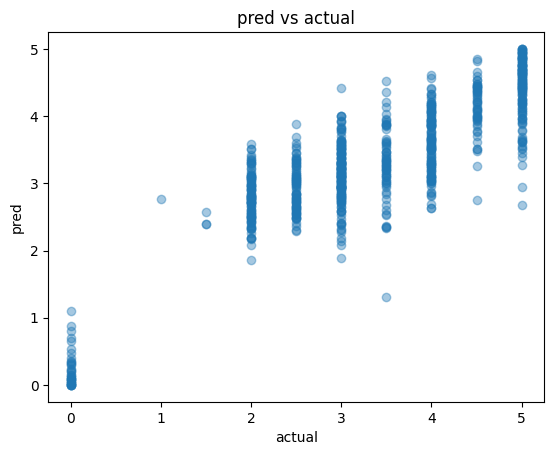

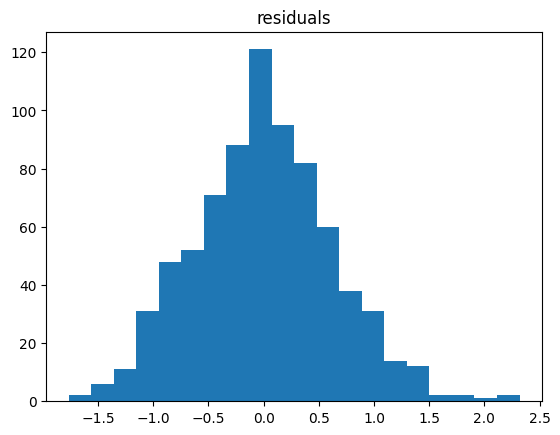

In [15]:
# pred-vs-actual and residuals (needs y, oof_r, oof_c)
import matplotlib.pyplot as plt
b = 0.5*oof_r + 0.5*oof_c
plt.figure()
plt.scatter(y, b, alpha=0.4)
plt.xlabel('actual')
plt.ylabel('pred')
plt.title('pred vs actual')
plt.show()
plt.figure()
plt.hist(y - b, bins=20)
plt.title('residuals')
plt.show()


## 5 Conclusion
Stack wins by variance reduction. Limits: ASR noise, GPU quota. Future: fine-tune.
